# OpenGL backends, frames and video

MuJoCo draws pictures through OpenGL, and a computer can offer up to three ways to do that (`glfw`, `egl`, `osmesa`). ARIEL tests them once, saves which ones work in `mujoco_user_config.json`, and picks one before MuJoCo loads, so a machine with no usable backend never crashes at import. `ariel.rendering` then turns simulations into pictures and videos.

In this notebook you read the backend report for this machine, write a test video from made-up frames (this needs no OpenGL, only a video codec), and, when a backend works, render a real frame and a real video of a robot. Without a backend the last section says so and everything above it still runs.

`ariel.rendering` comes first. Importing it tests the OpenGL backends (once) and chooses one, and MuJoCo reads that choice when it loads, so no cell before this one may import `mujoco`.

In [1]:
from ariel.rendering import (  # chooses the OpenGL backend before MuJoCo loads
    VideoRecorder,
    single_frame_renderer,
    video_renderer,
)
from ariel.simulators import compile_model

One-off setup: testing which OpenGL backends work on this machine. The result is saved to mujoco_user_config.json; 
this will not be repeated.

Output()

In [2]:
# Standard library
import os
from pathlib import Path

In [3]:
# Third-party libraries
import cv2
import matplotlib.pyplot as plt
import mujoco
import numpy as np
from rich.table import Table

In [4]:
# Local libraries
from ariel import console
from ariel.body_phenotypes.robogen_lite.prebuilt_robots import john_set
from ariel.opengl.gl_backend import config_path, read_config
from ariel.simulation import SimpleFlatWorld

In [5]:
# Settings and the output folder
FRAMES = 30
FPS = 30
WIDTH = 160
HEIGHT = 120
RED_MIN = 150  # a pixel counts as red above this red value
OTHER_MAX = 100  # and below this green value
DATA = Path.cwd() / "__data__" / "opengl_and_video"
DATA.mkdir(parents=True, exist_ok=True)

## Which backends work here

Importing `ariel.rendering` (done above) made sure the backend test had run. `read_config` reads the saved report. Each backend is either OK, with the time it needed to draw a test frame, or failed, with the reason. `selected` is the backend ARIEL chose; it is empty when none works. A machine where all three fail is normal for a server without a display.

In [6]:
config = read_config(config_path())
assert config is not None, config_path()
table = Table(title=f"OpenGL backends on {config.platform}")
for column in ("backend", "works", "test frame (ms)", "error"):
    table.add_column(column, overflow="fold")
for name, result in config.backends.items():
    table.add_row(
        name,
        "yes" if result.ok else "no",
        "" if result.render_ms is None else f"{result.render_ms:.1f}",
        result.error or "",
    )
console.print(table)
console.print(
    f"selected: {config.selected}, MUJOCO_GL={os.environ.get('MUJOCO_GL')}"
)

                                             OpenGL backends on linux                                              
┏━━━━━━━━━┳━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ backend ┃ works ┃ test frame (ms) ┃ error                                                                       ┃
┡━━━━━━━━━╇━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ glfw    │ no    │                 │ FatalError: an OpenGL platform library has not been loaded into this        │
│         │       │                 │ process, this most likely means that a valid OpenGL context has not been    │
│         │       │                 │ created before mjr_makeContext was called                                   │
│ egl     │ yes   │ 0.5             │                                                                             │
│ osmesa  │ yes   │ 0.4             │                                                                             │
└─────────┴───────┴─────────────────┴─────────────────────────────────────────────────────────────────────────────┘

selected: osmesa, MUJOCO_GL=osmesa

In [7]:
assert config.backends  # at least one backend was tested
working = [name for name, result in config.backends.items() if result.ok]
assert (config.selected is None) == (not working)
assert config.selected is None or config.selected in working

## Write a video from made-up frames

`VideoRecorder` writes frames to a video file with OpenCV. Here the frames are a coloured square that slides across the picture, so we know exactly what the video should show. The recorder adds a timestamp to the file name and tries other codecs if the first one is missing.

In [8]:
recorder = VideoRecorder(
    file_name="slide",
    output_folder=DATA,
    width=WIDTH,
    height=HEIGHT,
    fps=FPS,
)
for index in range(FRAMES):
    frame = np.zeros((HEIGHT, WIDTH, 3), dtype=np.uint8)
    left = index * (WIDTH - 20) // (FRAMES - 1)
    frame[50:70, left : left + 20] = (255, 0, 0)  # red, in RGB
    recorder.write(frame)
recorder.release()
video = max(DATA.glob("slide_*"), key=lambda path: path.stat().st_mtime)
console.print(
    f"{video.name}: {video.stat().st_size} bytes, {recorder.frame_count} frames"
)
assert recorder.frame_count == FRAMES
assert video.stat().st_size > 0

slide_20261022_035812.mp4: 4694 bytes, 30 frames

## Read it back

OpenCV opens the file again. The frame count must match what we wrote, and the red square must be at the left in the first frame and at the right in the last.

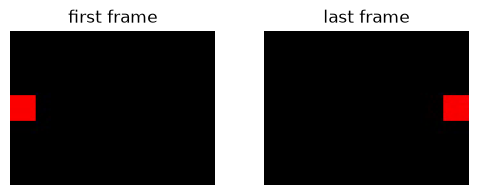

In [9]:
capture = cv2.VideoCapture(str(video))
frames = []
while True:
    ok, image = capture.read()
    if not ok:
        break
    frames.append(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
capture.release()
fig, axes = plt.subplots(1, 2, figsize=(6, 2))
for axis, picture, title in zip(
    axes, (frames[0], frames[-1]), ("first frame", "last frame"), strict=True
):
    axis.imshow(picture)
    axis.set_title(title)
    axis.axis("off")
plt.show()

In [10]:
def red_centre(picture: np.ndarray) -> float:
    # average column of the red pixels (compression blurs the edges)
    red = (picture[:, :, 0] > RED_MIN) & (picture[:, :, 1] < OTHER_MAX)
    return float(np.nonzero(red)[1].mean())


assert len(frames) == FRAMES
assert red_centre(frames[0]) < WIDTH / 4
assert red_centre(frames[-1]) > 3 * WIDTH / 4

## A real frame and video (needs OpenGL)

The first cell tries to open a tiny render context. If it fails, the second prints a message. Otherwise it renders the prebuilt gecko standing in a flat world as one picture with `single_frame_renderer` and as a one-second video with `video_renderer`.

In [11]:
try:
    mujoco.Renderer(
        compile_model(mujoco.MjSpec.from_string("<mujoco/>")), 8, 8
    ).close()
    OPENGL = True
except mujoco.FatalError:
    OPENGL = False
console.print(f"OpenGL works: {OPENGL}")

OpenGL works: True

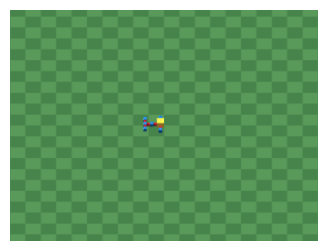

In [12]:
if OPENGL:
    world = SimpleFlatWorld(load_precompiled=False)
    world.spawn(john_set.gecko_small().spec)
    model = world.compile()
    data = mujoco.MjData(model)
    picture = single_frame_renderer(
        model, data, steps=100, width=320, height=240
    )
    plt.figure(figsize=(4, 3))
    plt.imshow(picture)
    plt.axis("off")
    plt.show()
    assert np.asarray(picture).std() > 0  # not one flat colour
    real = VideoRecorder(
        file_name="gecko", output_folder=DATA, width=320, height=240, fps=FPS
    )
    video_renderer(model, data, duration=1.0, video_recorder=real)
    assert real.frame_count > 0
else:
    console.print("No working OpenGL backend: skipped the real render.")